In [11]:
# 1. Import libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay
)

RANDOM_STATE = 42


In [12]:
# 2. Load and inspect the dataset
df = pd.read_csv("diabetes.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumn information:")
df.info()
print("\\nMissing values:")
display(df.isnull().sum())


Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


\nColumn information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
\nMissing values:


,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [13]:
# 3. Separate features and target
target = "Outcome"
expected_features = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"
]

missing_columns = [c for c in expected_features + [target] if c not in df.columns]
if missing_columns:
    raise ValueError(f"CSV is missing required columns: {missing_columns}")

X = df[expected_features].copy()
y = df[target].copy()

print("Target distribution:")
display(y.value_counts().rename(index={0: "No diabetes", 1: "Diabetes"}))


Target distribution:


,count
Outcome,
No diabetes,500
Diabetes,268


In [14]:
# 4. Replace medically invalid zero values with NaN
# Zero is valid for Pregnancies, but generally invalid for these measurements.
zero_as_missing = [
    "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"
]
X[zero_as_missing] = X[zero_as_missing].replace(0, np.nan)

print("Missing values after zero handling:")
display(X.isnull().sum())


Missing values after zero handling:


,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0


In [15]:
# 5. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 614
Testing rows: 154


In [16]:
# 6. Build preprocessing + Logistic Regression pipeline
# Median imputation and scaling are fitted only on training data.
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

model.fit(X_train, y_train)
print("Model training completed.")


Model training completed.


In [17]:
# 7. Make predictions and calculate evaluation metrics
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_probability)
}

metrics_df = pd.DataFrame(
    {"Metric": metrics.keys(), "Score": [round(v, 3) for v in metrics.values()]}
)
display(metrics_df)
print("\\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))


,Metric,Score
0,Accuracy,0.734
1,Precision,0.603
2,Recall,0.704
3,F1-score,0.650
4,ROC-AUC,0.813


\nClassification report:
              precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154



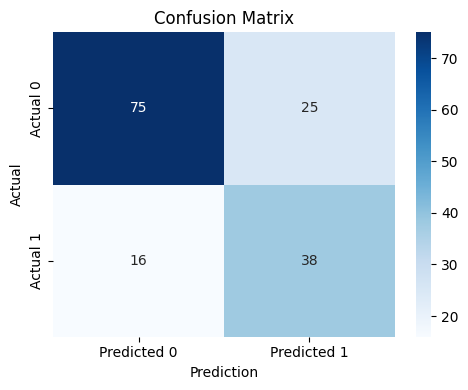

TN=75, FP=25, FN=16, TP=38


In [18]:
# 8. Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.title("Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")


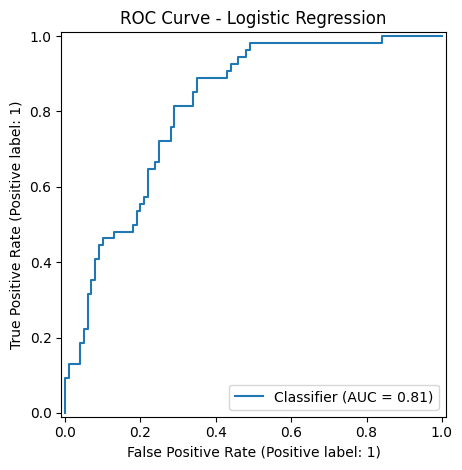

In [19]:
# 9. ROC curve
RocCurveDisplay.from_predictions(y_test, y_probability)
plt.title("ROC Curve - Logistic Regression")
plt.tight_layout()
plt.show()


,Feature,Coefficient
1,Glucose,1.183483
5,BMI,0.709592
0,Pregnancies,0.372902
6,DiabetesPedigreeFunction,0.287734
7,Age,0.186434
3,SkinThickness,0.013980
2,BloodPressure,-0.014612
4,Insulin,-0.044609


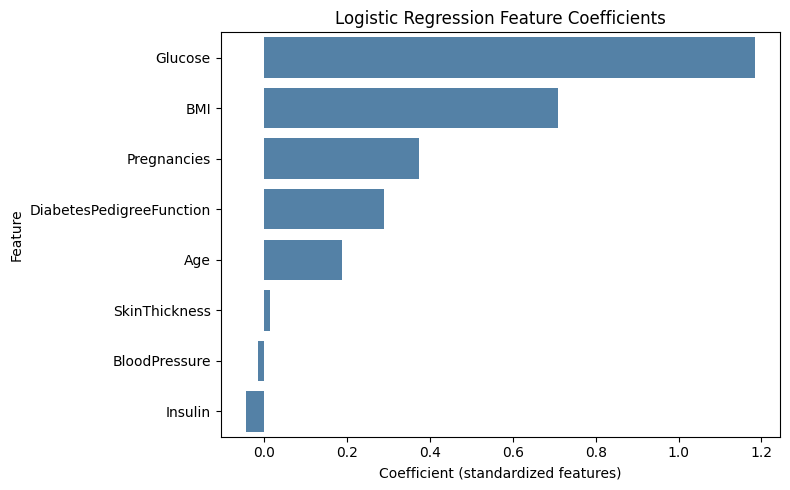

In [20]:
# 10. Interpret model coefficients
# Coefficients are on standardized feature scales.
classifier = model.named_steps["classifier"]
coef_df = pd.DataFrame({
    "Feature": expected_features,
    "Coefficient": classifier.coef_[0]
}).sort_values("Coefficient", ascending=False)

display(coef_df)

plt.figure(figsize=(8, 5))
sns.barplot(data=coef_df, x="Coefficient", y="Feature", color="steelblue")
plt.title("Logistic Regression Feature Coefficients")
plt.xlabel("Coefficient (standardized features)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()
